# CNN-LSTM-CTC: prepare the data

We keep the existing splits. For each dataset, we build character IDs from **training text only**, resize images, and inspect a batch. No model training or test-set evaluation happens here.

Select the existing project Python environment. Bentham must already be downloaded. See `README.md` beside this notebook for the input and CTC policies.


In [1]:
from pathlib import Path
import sys
import json
import platform
from datetime import datetime, timezone
from importlib.metadata import version

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/load_dataset/iam.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import torch
import matplotlib.pyplot as plt
import numpy as np
from src.evaluation.recognition import normalize_text
from torch.utils.data import DataLoader
from src.load_dataset.iam import load_iam_dataset
from src.load_dataset.bentham import load_bentham_dataset, REVISION, ARCHIVES
from src.training.ctc_data import (
    CharacterVocabulary, CTCImagePreparation, CTCLineDataset, collate_ctc_lines,
)

REFERENCE = ROOT / "results/validation/denoising/20261112T000633091905Z/metadata.json"
reference = json.loads(REFERENCE.read_text(encoding="utf-8"))
assert reference["split"] == "validation"
assert REVISION == reference["bentham_revision"]
SEED = 5112
BATCH_SIZE = 4
preparation = CTCImagePreparation(height=64)

# Keep the actual figures for export alongside preparation metadata.
preparation_figures = {}


## Open the existing training and validation splits

The IAM revision and validation selections match the teammate's study. Validation is restricted to its saved 100 lines per dataset. We do not open the test split.


In [2]:
train_splits = {
    "iam": load_iam_dataset(split="train", revision=reference["iam_revision"]),
    "bentham": load_bentham_dataset(split="train"),
}
validation_splits = {
    "iam": load_iam_dataset(split="validation", revision=reference["iam_revision"]),
    "bentham": load_bentham_dataset(split="validation"),
}
for name in train_splits:
    assert len(validation_splits[name]) == reference["full_split_sizes"][name]
    print(f"{name}: {len(train_splits[name])} training lines; "
          f"{len(reference['sample_indices'][name])} selected validation lines")


iam: 6482 training lines; 100 selected validation lines
bentham: 9198 training lines; 100 selected validation lines


## Turn training characters into numbers and make batches

Each dataset gets its own training-derived vocabulary. ID `0` is the CTC blank, not a character. Unknown validation characters are reported, never added to the alphabet. Original text is retained alongside whitespace-normalized labels.


In [3]:
vocabularies, train_loaders, validation_loaders, records = {}, {}, {}, {}
for name, source in train_splits.items():
    vocabulary = CharacterVocabulary.from_training_split(source)
    vocabularies[name] = vocabulary
    indices = reference["sample_indices"][name]
    assert len(indices) == 100
    selected_validation = validation_splits[name].select(indices)
    unknown = vocabulary.unknown_characters(selected_validation["text"])
    train_data = CTCLineDataset(source, vocabulary, preparation)
    validation_data = CTCLineDataset(validation_splits[name], vocabulary, preparation, indices=indices)
    train_loaders[name] = DataLoader(
        train_data, batch_size=BATCH_SIZE, shuffle=True,
        generator=torch.Generator().manual_seed(SEED), num_workers=0,
        collate_fn=collate_ctc_lines,
    )
    # Labels with unseen characters cannot be encoded for validation CTC loss.
    validation_loaders[name] = None if unknown else DataLoader(
        validation_data, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=0, collate_fn=collate_ctc_lines,
    )
    records[name] = {
        "revision": reference["iam_revision"] if name == "iam" else REVISION,
        "train_count": len(source), "train_fingerprint": source._fingerprint,
        "validation_split_count": len(validation_splits[name]),
        "validation_fingerprint": validation_splits[name]._fingerprint,
        "validation_source_indices": indices,
        "unknown_validation_characters": unknown,
        "vocabulary": vocabulary.to_config(),
    }
    print(f"{name}: {len(vocabulary.characters)} characters + CTC blank")
    print("Unknown validation characters:", repr(unknown))
    if unknown:
        print("Validation label loading is blocked: decide an alphabet policy without using held-out text to build it.")


iam: 79 characters + CTC blank
Unknown validation characters: []
bentham: 93 characters + CTC blank
Unknown validation characters: []


## See the original image and the model input

These are real **training images**, one from each dataset. We choose the first line with at least 12 characters to make the example readable. The original is preserved. Preparation makes a grayscale image with height 64 and keeps its proportions; it does not run denoising, deskewing, or CLAHE.


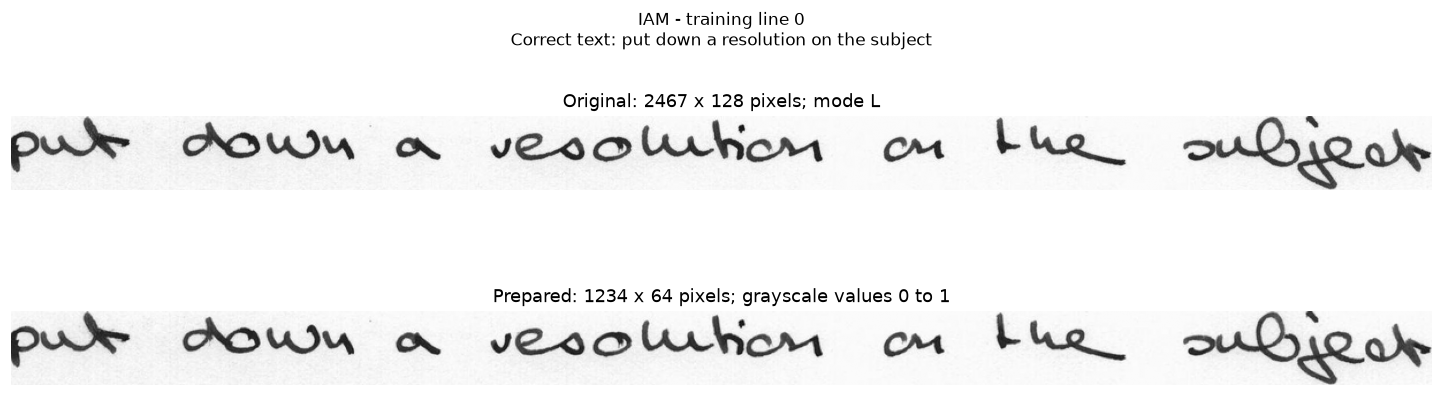

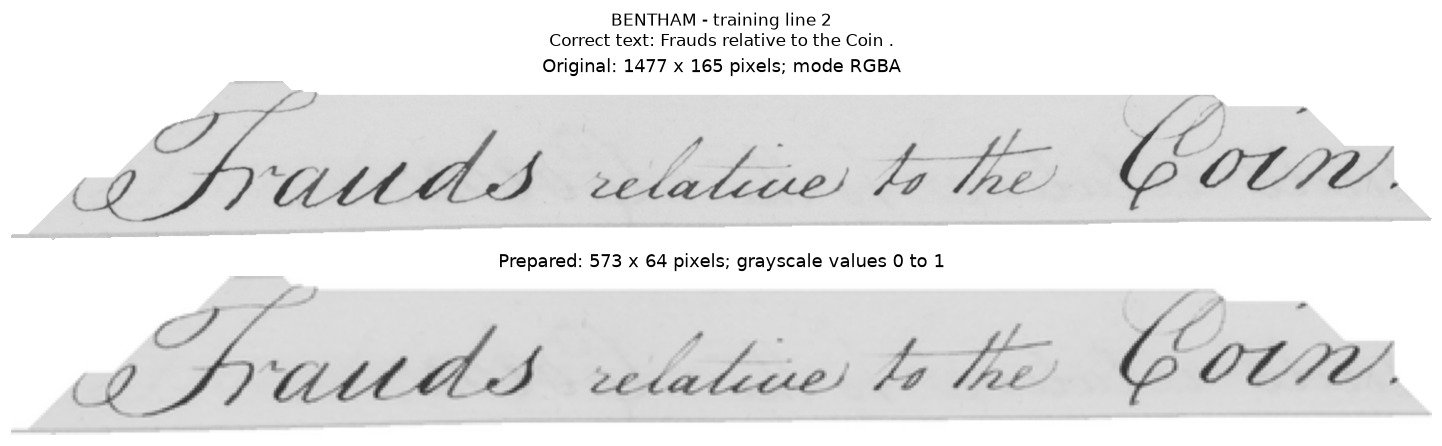

In [4]:
example_indices = {}
for name, source in train_splits.items():
    example_index = next(i for i, text in enumerate(source["text"])
                         if len(normalize_text(text)) >= 12)
    example_indices[name] = example_index
    row = source[example_index]
    original = row["image"]
    prepared = preparation(original)
    fig, axes = plt.subplots(2, 1, figsize=(13, 4), layout="constrained")
    axes[0].imshow(original, cmap="gray", vmin=0, vmax=255)
    axes[0].set_title(f"Original: {original.width} x {original.height} pixels; mode {original.mode}")
    axes[1].imshow(prepared[0].numpy(), cmap="gray", vmin=0, vmax=1)
    axes[1].set_title(f"Prepared: {prepared.shape[2]} x {prepared.shape[1]} pixels; grayscale values 0 to 1")
    for ax in axes:
        ax.axis("off")
    fig.suptitle(f"{name.upper()} - training line {example_index}\nCorrect text: {normalize_text(row['text'])}", fontsize=11)
    preparation_figures[f"{name}_original_and_prepared"] = fig
    plt.show()


## A real word: letters to numbers and back

We take a word from each example's correct transcription. The table shows the actual character IDs from that dataset's training vocabulary. The same character always has the same ID **within that vocabulary**. IAM and Bentham can have different IDs.

This is label encoding, not a model prediction. No image has been recognised yet. CTC blank is ID 0; it is never inserted into the correct-answer label. The CNN and LSTM will later learn to predict characters from the picture.


IAM word: 'resolution' -> IDs: [71, 58, 72, 68, 65, 74, 73, 62, 68, 67] -> decoded label: 'resolution'
BENTHAM word: 'relative' -> IDs: [76, 63, 70, 59, 78, 67, 80, 63] -> decoded label: 'relative'


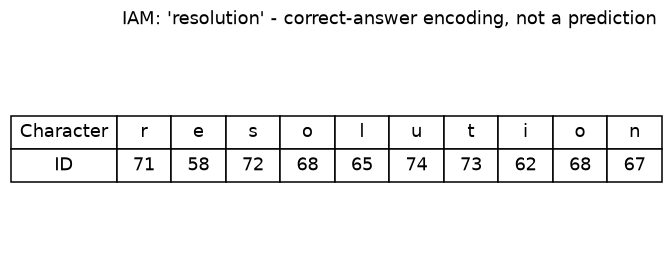

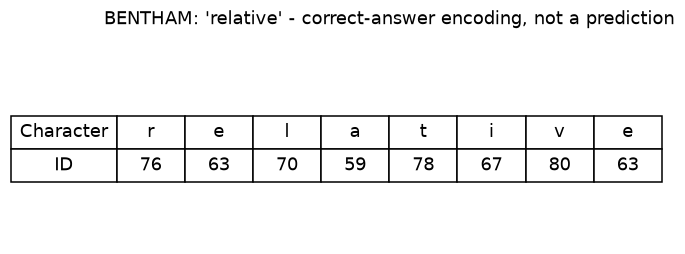

In [5]:
for name, source in train_splits.items():
    text = normalize_text(source[example_indices[name]]["text"])
    words = [word for word in text.split() if word.isalpha()]
    word = max(words, key=len) if words else text.split()[0]
    vocabulary = vocabularies[name]
    ids = vocabulary.encode(word).tolist()
    decoded = vocabulary.decode_labels(ids)
    assert decoded == word
    print(f"{name.upper()} word: {word!r} -> IDs: {ids} -> decoded label: {decoded!r}")
    fig, ax = plt.subplots(figsize=(max(6, len(word) * 0.6), 2.2), layout="constrained")
    ax.axis("off")
    table = ax.table(cellText=[list(word), ids], rowLabels=["Character", "ID"],
                     cellLoc="center", rowLoc="center", loc="center")
    table.auto_set_font_size(False)
    table.set_fontsize(12)
    table.scale(1, 1.8)
    ax.set_title(f"{name.upper()}: {word!r} - correct-answer encoding, not a prediction", pad=20)
    preparation_figures[f"{name}_word_to_ids"] = fig
    plt.show()


## How much data do we have?

The left chart shows the full predefined splits. Test counts come **only from saved experiment metadata**; we do not load test images or read their text. The right chart shows the exact 100-line validation subset used here and the teammate's 250-line test subset reserved for later comparison. These subsets belong to the existing splits; they are not new splits.


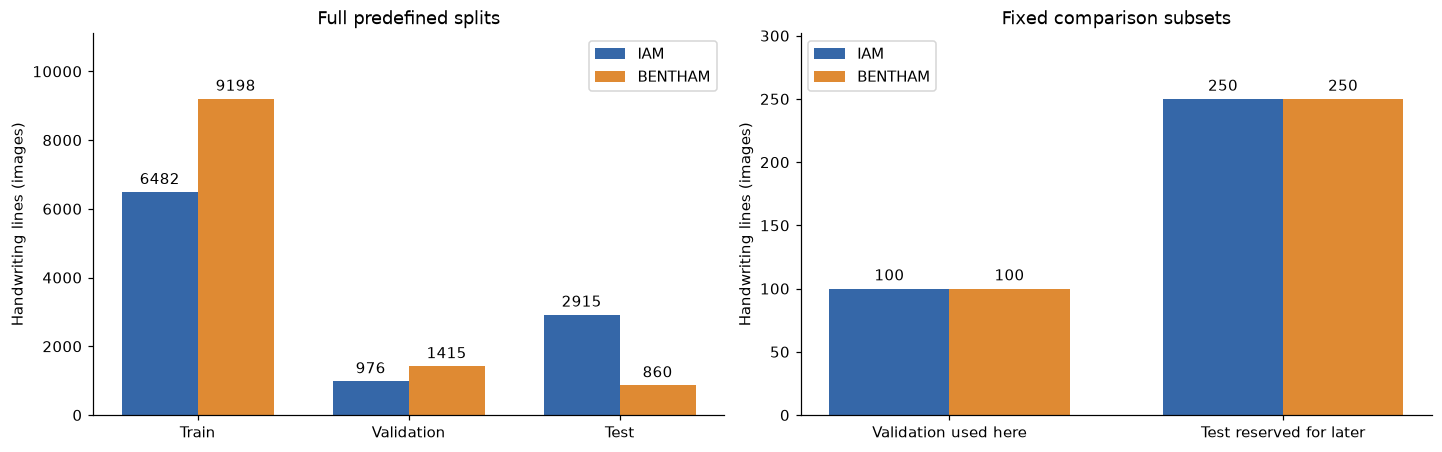

In [6]:
test_metadata_path = ROOT / "results/test/experiment_a/20261112T024202644804Z/metadata.json"
test_reference = json.loads(test_metadata_path.read_text(encoding="utf-8"))
assert test_reference["split"] == "test"
fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
colors = ["#3567a8", "#df8a33"]
x = np.arange(3)
for offset, (name, source) in enumerate(train_splits.items()):
    counts = [len(source), len(validation_splits[name]),
              test_reference["datasets"][name]["split_size"]]
    bars = axes[0].bar(x + (offset - 0.5) * 0.36, counts, width=0.36,
                       label=name.upper(), color=colors[offset])
    axes[0].bar_label(bars, padding=3)
axes[0].set_xticks(x, ["Train", "Validation", "Test"])
axes[0].set_title("Full predefined splits")
axes[0].legend()
for offset, name in enumerate(train_splits):
    counts = [len(reference["sample_indices"][name]), len(test_reference["sample_indices"][name])]
    bars = axes[1].bar(np.arange(2) + (offset - 0.5) * 0.36, counts, width=0.36,
                       label=name.upper(), color=colors[offset])
    axes[1].bar_label(bars, padding=3)
axes[1].set_xticks(np.arange(2), ["Validation used here", "Test reserved for later"])
axes[1].set_title("Fixed comparison subsets")
axes[1].legend()
for ax in axes:
    ax.set_ylabel("Handwriting lines (images)")
    ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
    ax.spines[["top", "right"]].set_visible(False)
preparation_figures["dataset_split_counts"] = fig
plt.show()


## Are the training lines short or long?

Each bar counts training lines of similar text length. The horizontal axis counts characters **after the same whitespace normalization used for labels**; it includes spaces and punctuation. Long text needs more CTC output positions. This graph describes training data, not recognition accuracy.


iam: shortest=1, median=43, longest=80 characters
bentham: shortest=1, median=53, longest=105 characters


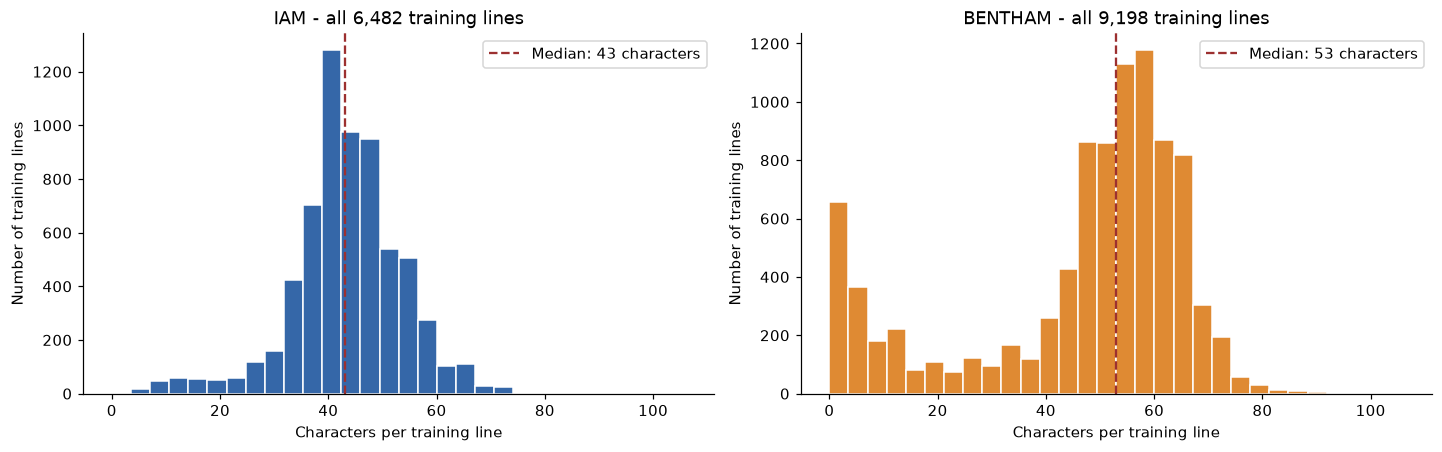

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout="constrained", sharex=True)
lengths_by_dataset = {
    name: np.array([len(normalize_text(text)) for text in source["text"]])
    for name, source in train_splits.items()
}
maximum = max(int(lengths.max()) for lengths in lengths_by_dataset.values())
bins = np.linspace(0, maximum + 1, 31)
for ax, (name, lengths), color in zip(axes, lengths_by_dataset.items(), colors):
    ax.hist(lengths, bins=bins, color=color, edgecolor="white")
    ax.axvline(float(np.median(lengths)), color="#9c3030", linestyle="--",
               label=f"Median: {np.median(lengths):.0f} characters")
    ax.set_title(f"{name.upper()} - all {len(lengths):,} training lines")
    ax.set_xlabel("Characters per training line")
    ax.set_ylabel("Number of training lines")
    ax.legend()
    ax.spines[["top", "right"]].set_visible(False)
    print(f"{name}: shortest={lengths.min()}, median={np.median(lengths):.0f}, longest={lengths.max()} characters")
preparation_figures["training_text_lengths"] = fig
plt.show()


## Inspect one training batch from each dataset

`images` has shape **[batch, 1 grayscale channel, height, padded width]**. `image_widths` excludes padding. The future CNN must turn those pixel widths into CTC output lengths. This preview consumes one batch; rerun the previous cell to reset the seeded loaders.


iam image batch: (4, 1, 64, 1452)
Pixel widths: [786, 708, 1061, 1452]
Label lengths: [59, 49, 44, 61]
Minimum CTC time steps: [59, 51, 44, 65]
Original text: 'experiment from which the organisers hoped to learn as much'
Encoded text: [58, 77, 69, 58, 71, 62, 66, 58, 67, 73, 1, 59, 71, 68, 66, 1, 76, 61, 62, 56, 61, 1, 73, 61, 58, 1, 68, 71, 60, 54, 67, 62, 72, 58, 71, 72, 1, 61, 68, 69, 58, 57, 1, 73, 68, 1, 65, 58, 54, 71, 67, 1, 54, 72, 1, 66, 74, 56, 61]
Decoded label: experiment from which the organisers hoped to learn as much
bentham image batch: (4, 1, 64, 747)
Pixel widths: [747, 592, 55, 291]
Label lengths: [47, 34, 1, 11]
Minimum CTC time steps: [48, 34, 1, 11]
Original text: 'as in the words acuteness , and acumen :  in the\n'
Encoded text: [59, 77, 1, 67, 72, 1, 78, 66, 63, 1, 81, 73, 76, 62, 77, 1, 59, 61, 79, 78, 63, 72, 63, 77, 77, 1, 11, 1, 59, 72, 62, 1, 59, 61, 79, 71, 63, 72, 1, 25, 1, 67, 72, 1, 78, 66, 63]
Decoded label: as in the words acuteness , and acumen : in 

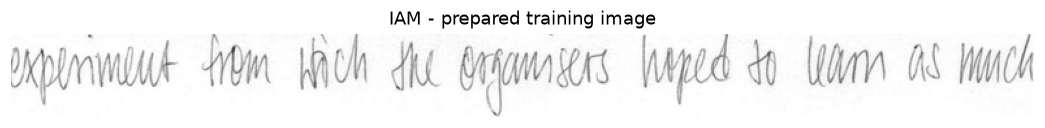

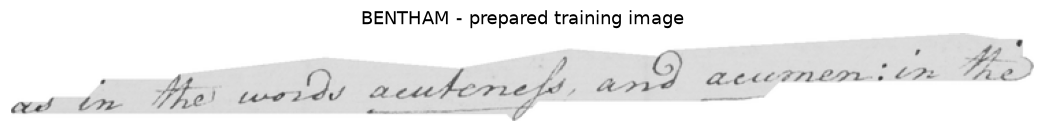

In [8]:
for name, loader in train_loaders.items():
    batch = next(iter(loader))
    print(name, "image batch:", tuple(batch["images"].shape))
    print("Pixel widths:", batch["image_widths"].tolist())
    print("Label lengths:", batch["target_lengths"].tolist())
    print("Minimum CTC time steps:", batch["minimum_ctc_timesteps"].tolist())
    print("Original text:", repr(batch["ground_truth"][0]))
    first_length = int(batch["target_lengths"][0])
    print("Encoded text:", batch["targets"][:first_length].tolist())
    print("Decoded label:", vocabularies[name].decode_labels(batch["targets"][:first_length]))
    plt.figure(figsize=(12, 2))
    plt.imshow(batch["images"][0, 0, :, :int(batch["image_widths"][0])], cmap="gray", vmin=0, vmax=1)
    plt.title(f"{name.upper()} - prepared training image")
    plt.axis("off")
    plt.show()


## Save the preparation settings

This writes small metadata and vocabulary files only. It does not copy the dataset or save training results.


In [9]:
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
output = ROOT / "results/cnn_lstm_ctc/data_preparation" / run_id
output.mkdir(parents=True, exist_ok=False)
metadata = {
    "phase": "data_preparation_only", "seed": SEED, "batch_size": BATCH_SIZE,
    "validation_reference": str(REFERENCE.relative_to(ROOT)),
    "mandatory_input": preparation.to_config(), "datasets": records,
    "bentham_archive_sha256_expected": ARCHIVES,
    "bentham_source_record_present": (ROOT / "data/bentham/source.json").is_file(),
    "python": platform.python_version(),
    "versions": {name: version(name) for name in ("torch", "datasets", "numpy", "Pillow", "jiwer")},
    "test_loaded": False, "training_started": False,
    "split_count_test_metadata": str(test_metadata_path.relative_to(ROOT)),
    "visualization_training_source_indices": example_indices,
    "figure_files": [name + ".png" for name in preparation_figures],
}
(output / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
for name, vocabulary in vocabularies.items():
    (output / f"{name}_vocabulary.json").write_text(
        json.dumps(vocabulary.to_config(), indent=2), encoding="utf-8")
print("Saved preparation settings:", output)

for name, fig in preparation_figures.items():
    fig.savefig(output / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.close(fig)
print(f"Saved {len(preparation_figures)} example and graph images alongside metadata.")


Saved preparation settings: C:\Users\chirayu ubale\OneDrive\Desktop\Research Project\results\cnn_lstm_ctc\data_preparation\20261114T211708884735Z
Saved 6 example and graph images alongside metadata.
